# 02 · Preprocessing of the major ions (Figure 3)

Code for: El Farchouni, A., et al. *Groundwater Recharge Mechanisms in the Haouz-Mejjate Aquifer (Morocco): Insights from Environmental Tracers and Self-Organizing Maps.* Groundwater for Sustainable Development, 101706. https://doi.org/10.1016/j.gsd.2026.101706

**What this notebook does**

The seven major ions of the 406 complete samples are transformed in three steps before PCA, SOM and HCA (Haselbeck et al., 2019; Bastianoni et al., 2021):
1. **mg/L → meq/L** (equivalent weights), so that ions are compared by charge, not by mass.
2. **meq/L → relative %** of the total ionic content of each sample, so that fresh and highly mineralized waters are compared by their ionic signature.
3. **relative % → z-score** (zero mean, unit variance per ion), so that every ion weighs equally in the Euclidean distances. **This is the SOM input.**

The four stages are shown in **Figure 3** of the article.

| | |
|---|---|
| **Input** | `outputs/intermediate/data_complete_major_ions.xlsx` (from `01_data_quality_control.ipynb`) |
| **Outputs** | `outputs/intermediate/data_preprocessed_full.xlsx` (406 samples, all stages + metadata), `data_scaled_SOM_input.xlsx` (SOM matrix), `scaler_parameters.csv` |
| **Figure** | `outputs/figures/Figure3_composite_boxplots_4stages.png` / `.svg` |
| **Next notebook** | `02_hydrochemistry/01_scatter_plots.ipynb` |

### <font color='orange'> **1) Packages, settings and paths** </font>

In [1]:
# ── Packages ─────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.preprocessing import StandardScaler
from pathlib import Path
import warnings

# ── Settings ─────────────────────────────────────────────────────────
warnings.filterwarnings("ignore", category=UserWarning)
plt.rcParams.update({
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "font.size": 13,
    "axes.labelsize": 15,
    "axes.titlesize": 16,
    "axes.labelweight": "bold",
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
    "legend.title_fontsize": 13,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "black",
    "axes.grid": True,
    "grid.alpha": 0.3,
    "savefig.bbox": "tight",
    "savefig.transparent": False,
})

# ── Paths (built from the repository root, so they work on any computer) ──
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "data").is_dir() and (p / "notebooks").is_dir())
DIR_INTERMED = ROOT / "outputs" / "intermediate"
DIR_FIGURES  = ROOT / "outputs" / "figures"
for d in (DIR_INTERMED, DIR_FIGURES):
    d.mkdir(parents=True, exist_ok=True)

print("Package versions:")
for name, mod in [("numpy", np), ("pandas", pd), ("matplotlib", matplotlib),
                  ("seaborn", sns), ("scikit-learn", sklearn)]:
    print(f"  {name:14s} {mod.__version__}")

C:\Users\Admin\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


Package versions:
  numpy          1.26.4
  pandas         2.2.3
  matplotlib     3.7.2
  seaborn        0.12.2
  scikit-learn   1.9.0


### <font color='orange'> **2) Load the 406 complete samples** </font>

Output of `01_data_quality_control.ipynb`.

In [2]:
# ── Load the output of 01_data_quality_control.ipynb ────────────────
DATA_FILE = DIR_INTERMED / "data_complete_major_ions.xlsx"

print(f"Input file : {DATA_FILE.relative_to(ROOT)}  (exists: {DATA_FILE.is_file()})")

df = pd.read_excel(DATA_FILE)

# ── Define column groups ─────────────────────────────────────────────
MAJOR_IONS = ["Ca (mg/L)", "Mg (mg/L)", "Na (mg/L)", "K (mg/L)",
              "HCO3 (mg/L)", "Cl (mg/L)", "SO4 (mg/L)"]

META_COLS = [c for c in df.columns if c not in MAJOR_IONS]

ION_LABELS = [c.replace(" (mg/L)", "") for c in MAJOR_IONS]

# ── Quick summary ────────────────────────────────────────────────────
print(f"\nDataset shape: {df.shape[0]} samples × {df.shape[1]} columns")
print(f"Metadata cols: {META_COLS}")
print(f"Major ions   : {ION_LABELS}")
print(f"Missing vals : {df[MAJOR_IONS].isnull().sum().sum()} (should be 0)")

print(f"\n── Sample types ───────────────────────────────────────────")
print(df["Type"].value_counts().to_string())

print(f"\n── Preview ────────────────────────────────────────────────")
display(df.head())

Input file : outputs\intermediate\data_complete_major_ions.xlsx  (exists: True)

Dataset shape: 406 samples × 13 columns
Metadata cols: ['Reference', 'SampleID', 'Type', 'Sampling date', 'X', 'Y']
Major ions   : ['Ca', 'Mg', 'Na', 'K', 'HCO3', 'Cl', 'SO4']
Missing vals : 0 (should be 0)

── Sample types ───────────────────────────────────────────
Type
Groundwater    305
Spring          49
Stream          40
Snow             3
Dam              2
Rain             2
Irrigation       2
Tributary        2
Lac              1

── Preview ────────────────────────────────────────────────


,Reference,SampleID,Type,Sampling date,X,Y,Ca (mg/L),Mg (mg/L),Na (mg/L),K (mg/L),HCO3 (mg/L),Cl (mg/L),SO4 (mg/L)
0,"(EL FARCHOUNI et al., 2025)",S5,Lac,2025-01-10 00:00:00,266236.0,469982.0,26.4,2.88,75.0,1.0,274.5,14.20,3.460
1,"(EL FARCHOUNI et al., 2025)",S6,Spring,2025-01-10 00:00:00,269982.0,472108.0,48.0,4.80,5.0,5.0,164.7,3.55,3.249
2,"(EL FARCHOUNI et al., 2025)",S7,Spring,2025-01-10 00:00:00,269194.0,77219.0,140.8,4.80,10.0,10.0,427.0,7.10,27.690
3,"(EL FARCHOUNI et al., 2025)",S8,Spring,2025-01-11 00:00:00,279700.0,478756.0,51.2,7.68,5.0,2.0,170.8,7.10,12.520
4,"(EL FARCHOUNI et al., 2025)",S9,Spring,2025-01-11 00:00:00,280089.0,478353.0,88.0,12.96,10.0,5.0,262.3,10.65,13.580


### <font color='orange'> **3) Unit conversion: mg/L → meq/L** </font>

> Convert concentrations from mg/L to milliequivalents per liter (meq/L).  
> Formula: **meq/L = (mg/L × valence) / molar mass**  
> 
> **Why?** Removes bias from molar mass and charge differences. Without this, heavier ions (SO₄²⁻ = 96 g/mol) would dominate over lighter ones (Na⁺ = 23 g/mol) in distance calculations.  
> (Haselbeck et al., 2019; Bastianoni et al., 2021)

| Ion | Molar mass (g/mol) | Valence | Divisor (M/z) |
|-----|-------------------|---------|---------------|
| Ca²⁺ | 40.08 | 2 | 20.04 |
| Mg²⁺ | 24.31 | 2 | 12.15 |
| Na⁺ | 22.99 | 1 | 22.99 |
| K⁺ | 39.10 | 1 | 39.10 |
| HCO₃⁻ | 61.02 | 1 | 61.02 |
| Cl⁻ | 35.45 | 1 | 35.45 |
| SO₄²⁻ | 96.06 | 2 | 48.03 |

In [3]:
# ── 3.1  Define equivalent weights and convert mg/L → meq/L ─────────
# Equivalent weight = Molar mass / |Ionic charge|
# meq/L = mg/L / equivalent weight

equivalent_weights = {
    "Ca (mg/L)":   20.04,    # 40.08 / 2
    "Mg (mg/L)":   12.15,    # 24.31 / 2
    "Na (mg/L)":   22.99,    # 22.99 / 1
    "K (mg/L)":    39.10,    # 39.10 / 1
    "HCO3 (mg/L)": 61.02,   # 61.02 / 1
    "Cl (mg/L)":   35.45,    # 35.45 / 1
    "SO4 (mg/L)":  48.03,    # 96.06 / 2
}

# New column names for meq/L
IONS_MEQ = [c.replace("(mg/L)", "(meq/L)") for c in MAJOR_IONS]

# Apply conversion
for col_mg, col_meq in zip(MAJOR_IONS, IONS_MEQ):
    df[col_meq] = df[col_mg] / equivalent_weights[col_mg]

# ── Verification: show one example ──────────────────────────────────
print("── Conversion verification (first sample) ─────────────────\n")
print(f"{'Ion':<8s} {'mg/L':>10s} {'Eq. wt':>8s} {'meq/L':>10s}")
print("─" * 40)
for col_mg, col_meq in zip(MAJOR_IONS, IONS_MEQ):
    ion = col_mg.replace(" (mg/L)", "")
    print(f"{ion:<8s} {df[col_mg].iloc[0]:10.2f} {equivalent_weights[col_mg]:8.2f} {df[col_meq].iloc[0]:10.4f}")

print(f"\n── Summary statistics (meq/L) ─────────────────────────────\n")
display(df[IONS_MEQ].describe().round(4))

── Conversion verification (first sample) ─────────────────

Ion            mg/L   Eq. wt      meq/L
────────────────────────────────────────
Ca            26.40    20.04     1.3174
Mg             2.88    12.15     0.2370
Na            75.00    22.99     3.2623
K              1.00    39.10     0.0256
HCO3         274.50    61.02     4.4985
Cl            14.20    35.45     0.4006
SO4            3.46    48.03     0.0720

── Summary statistics (meq/L) ─────────────────────────────



,Ca (meq/L),Mg (meq/L),Na (meq/L),K (meq/L),HCO3 (meq/L),Cl (meq/L),SO4 (meq/L)
count,406.0000,406.0000,406.0000,406.0000,406.0000,406.0000,406.0000
mean,5.0273,5.1229,4.9046,6.0314,4.7833,5.1693,3.2107
std,3.4580,34.1542,7.8078,19.2056,1.9745,8.6251,10.3469
min,0.0449,0.0033,0.0043,0.0000,0.0656,0.0056,0.0010
25%,2.8652,1.0823,1.0874,0.0307,3.5988,0.5007,0.5793
50%,4.2642,2.3625,2.5760,0.0536,4.8121,2.1041,1.2669
75%,6.1112,4.3911,5.0327,0.1312,6.0738,6.3543,2.7351
max,21.6567,687.5720,57.7016,143.2992,12.4959,63.9281,162.1695


### <font color='orange'> **4) Relative concentrations (% of the total ionic content)** </font>

> Convert absolute meq/L into relative ionic composition.
> 
> **Formula:** relative % = (ion meq/L) / (total meq/L of the sample) × 100
> 
> **Why?** The SOM learning algorithm uses Euclidean distances between input vectors. When TDS varies over several orders of magnitude (e.g., fresh groundwater at ~5 meq/L vs. brine at ~500 meq/L), absolute concentrations would cause highly saline samples to dominate the distance calculations. By converting to relative proportions, we focus on the **ionic signature** (the shape of the hydrochemical fingerprint) rather than the absolute mineralization level. This makes fresh groundwater and brine comparable in terms of their chemical character.
> 
> (Haselbeck et al., 2019)
> 
> **Input:** meq/L columns (from section 3)  
> **Output:** Relative composition (%) - each sample sums to 100%

In [4]:
# ── 4.1  Compute relative concentrations (%) ────────────────────────

# Extract meq/L columns only (numeric matrix for calculation)
df_meq_only = df[IONS_MEQ].copy()

# Total ionic salinity per sample (sum of all 7 ions in meq/L)
total_meq = df_meq_only.sum(axis=1)

# Relative concentration: each ion / total × 100
# Result: each row sums to 100%
df_relative = df_meq_only.div(total_meq, axis=0) * 100

# Rename columns: "Ca (meq/L)" → "Ca (%)"
IONS_REL = [c.replace("(meq/L)", "(%)") for c in IONS_MEQ]
df_relative.columns = IONS_REL

# Add to main dataframe
for col in IONS_REL:
    df[col] = df_relative[col].values

# Also store total meq/L (useful for interpretation later)
df["Total_meq"] = total_meq.values

# ── Verification ────────────────────────────────────────────────────
print("── Relative concentrations computed ────────────────────────\n")
print(f"Each row sums to: {df_relative.sum(axis=1).unique().round(1)}")

print(f"\n── Verification (first 3 samples) ─────────────────────────\n")
verify = df[["SampleID"] + IONS_REL].head(3).copy()
verify["Sum (%)"] = df_relative.head(3).sum(axis=1).values
display(verify)

print(f"\n── Summary statistics (%) ─────────────────────────────────\n")
display(df[IONS_REL].describe().round(2))

── Relative concentrations computed ────────────────────────

Each row sums to: [100. 100. 100. 100. 100.]

── Verification (first 3 samples) ─────────────────────────



,SampleID,Ca (%),Mg (%),Na (%),K (%),HCO3 (%),Cl (%),SO4 (%),Sum (%)
0,S5,13.424156,2.415444,33.243220,0.260618,45.840668,4.081811,0.734082,100.0
1,S6,39.903296,6.581581,3.623233,2.130387,44.966247,1.668312,1.126944,100.0
2,S7,44.226631,2.486817,2.738041,1.609912,44.048852,1.260727,3.629019,100.0



── Summary statistics (%) ─────────────────────────────────



,Ca (%),Mg (%),Na (%),K (%),HCO3 (%),Cl (%),SO4 (%)
count,406.00,406.00,406.00,406.00,406.00,406.00,406.00
mean,21.71,11.89,13.54,7.28,24.28,13.34,7.96
std,9.49,6.52,8.44,20.34,12.37,10.78,7.51
min,0.25,0.47,0.09,0.00,0.27,0.04,0.31
25%,14.28,8.02,7.22,0.19,13.83,4.44,3.83
50%,22.01,11.32,12.19,0.34,25.56,9.98,5.87
75%,28.46,15.46,17.84,0.69,34.93,20.55,9.80
max,45.55,75.19,50.82,89.15,51.48,43.88,86.08


### <font color='orange'> **5) Standardization (z-score): the SOM input** </font>

> Standardize the relative concentrations to zero mean and unit variance.
> 
> **Formula:** z = (x − μ) / σ &nbsp;&nbsp; (per variable, across all samples)
> 
> **Why?** Even after converting to relative concentrations, some ions (e.g., HCO₃⁻ at ~25%) have systematically higher percentages than others (e.g., K⁺, below 1% in most samples). Since the SOM uses Euclidean distance, ions with larger ranges would dominate the learning and mask the contribution of less concentrated species. Standardization ensures that **every ion contributes equally** to the distance calculation.
> 
> (Haselbeck et al., 2019)
> 
> **Input:** Relative concentrations (%) from section 4  
> **Output:** Standardized matrix (z-scores) - **this is the final SOM input**

In [5]:
# ── 5.1  Z-score standardization on relative concentrations ─────────

# Extract relative concentration columns
df_rel_only = df[IONS_REL].copy()

# Apply StandardScaler (zero mean, unit variance per column)
scaler = StandardScaler()
data_scaled = scaler.fit_transform(df_rel_only)

# New column names: "Ca (%)" → "Ca (scaled)"
IONS_SCALED = [c.replace("(%)", "(scaled)") for c in IONS_REL]

# Store as dataframe
df_scaled = pd.DataFrame(data_scaled, columns=IONS_SCALED, index=df.index)

# Add to main dataframe
for col in IONS_SCALED:
    df[col] = df_scaled[col].values

# ── Verification: mean ≈ 0 and std ≈ 1 per variable ────────────────
print("── Standardization verification ────────────────────────────\n")
check = pd.DataFrame({
    "Ion": ION_LABELS,
    "Mean (should be ~0)": df_scaled.mean().round(6).values,
    "Std  (should be ~1)": df_scaled.std().round(6).values,
    "Min": df_scaled.min().round(2).values,
    "Max": df_scaled.max().round(2).values,
})
display(check)

print(f"\n── Preview (first 5 samples) ───────────────────────────────\n")
display(df[["SampleID"] + IONS_SCALED].head())

── Standardization verification ────────────────────────────



,Ion,Mean (should be ~0),Std (should be ~1),Min,Max
0,Ca,-0.0,1.001234,-2.26,2.51
1,Mg,-0.0,1.001234,-1.75,9.72
2,Na,0.0,1.001234,-1.60,4.42
3,K,0.0,1.001234,-0.36,4.03
4,HCO3,0.0,1.001234,-1.94,2.20
5,Cl,-0.0,1.001234,-1.23,2.84
6,SO4,-0.0,1.001234,-1.02,10.41



── Preview (first 5 samples) ───────────────────────────────



,SampleID,Ca (scaled),Mg (scaled),Na (scaled),K (scaled),HCO3 (scaled),Cl (scaled),SO4 (scaled)
0,S5,-0.873926,-1.454575,2.338034,-0.345596,1.745537,-0.859180,-0.963365
1,S6,1.918357,-0.815004,-1.177149,-0.253535,1.674755,-1.083261,-0.911015
2,S7,2.374262,-1.443618,-1.282200,-0.279161,1.600496,-1.121103,-0.577607
3,S8,1.722265,-0.380441,-1.222809,-0.320926,1.408740,-0.961263,-0.543960
4,S9,1.957787,-0.323426,-1.133663,-0.300677,1.226423,-0.982317,-0.715613


### <font color='orange'> **6) Figure 3: the four preprocessing stages** </font>

(a) mg/L (log₁₀), (b) meq/L (log₁₀), (c) relative %, (d) z-score.

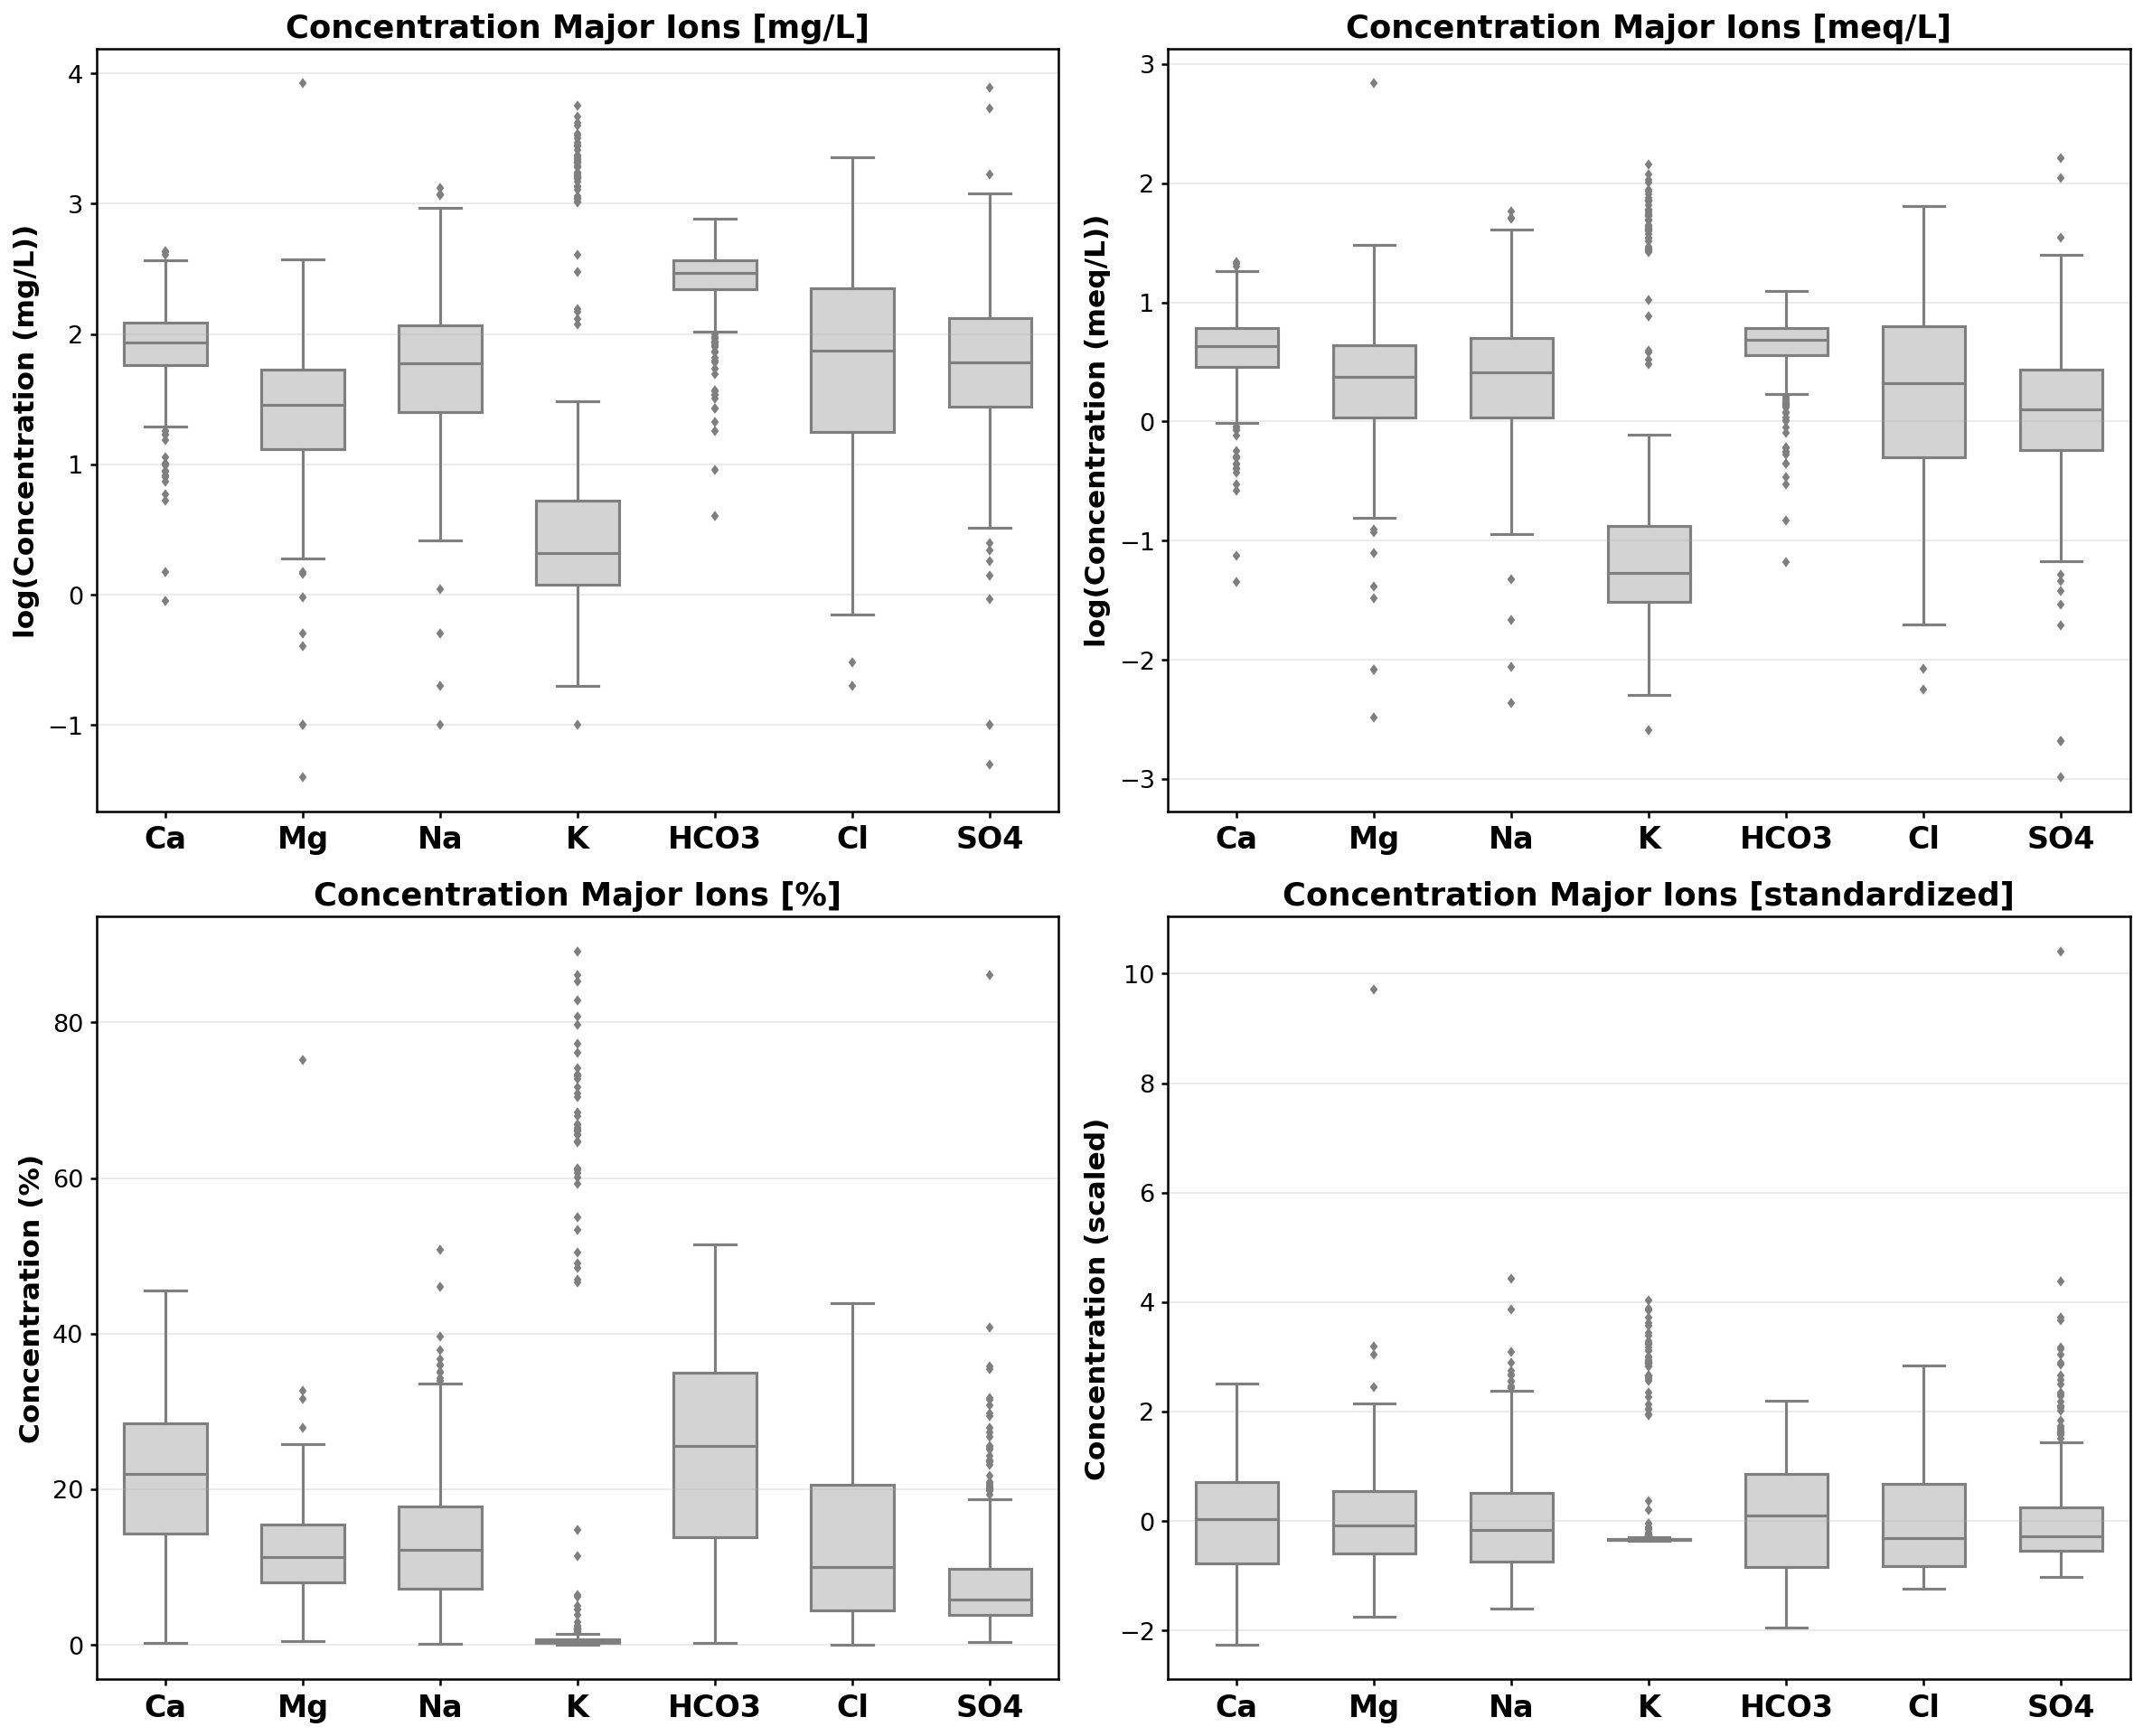

In [6]:
# ── Figure 3: composite boxplot of the 4 preprocessing stages (2×2) ─

fig, axes = plt.subplots(2, 2, figsize=(16, 13))

# ── Prepare data for each panel ──────────────────────────────────────
panels = [
    (df[MAJOR_IONS], ION_LABELS, "Concentration Major Ions [mg/L]", "log(Concentration (mg/L))", True),
    (df[IONS_MEQ],   ION_LABELS, "Concentration Major Ions [meq/L]", "log(Concentration (meq/L))", True),
    (df[IONS_REL],   ION_LABELS, "Concentration Major Ions [%]", "Concentration (%)", False),
    (df[IONS_SCALED],ION_LABELS, "Concentration Major Ions [standardized]", "Concentration (scaled)", False),
]

for idx, (data, labels, title, ylabel, use_log) in enumerate(panels):
    row = idx // 2
    col = idx % 2
    ax = axes[row, col]

    df_plot = data.copy()
    df_plot.columns = labels

    if use_log:
        df_plot = df_plot.replace(0, np.nan)
        df_plot = np.log10(df_plot)

    df_long = df_plot.melt(var_name="Ion", value_name="Value")

    sns.boxplot(
        data=df_long,
        x="Ion",
        y="Value",
        color="lightgray",
        width=0.6,
        fliersize=3,
        ax=ax,
    )

    ax.set_title(title, fontsize=17, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel(ylabel, fontsize=15, fontweight="bold")
    ax.set_xticklabels(ax.get_xticklabels(), fontsize=16, fontweight="bold")
    ax.tick_params(axis="y", labelsize=13)

    # Black axes
    for spine in ax.spines.values():
        spine.set_edgecolor("black")
        spine.set_linewidth(1.2)
    ax.tick_params(axis="both", colors="black", width=1.2)

plt.tight_layout()
fig.savefig(DIR_FIGURES / "Figure3_composite_boxplots_4stages.png", dpi=800)
plt.show()

### <font color='orange'> **7) Export** </font>

> Export a single comprehensive Excel file containing all transformations + metadata.  
> This file is the input of `03_PCA_SOM_HCA/01_PCA_SOM_training.ipynb` and `02_HCA_clustering.ipynb`.  
> The SOM trains on the **scaled columns only**, but metadata + original values are needed for interpretation.

In [7]:
# ── 6.1  Export comprehensive dataset ────────────────────────────────

# Verify column structure before export
print("── Final dataframe columns ────────────────────────────────\n")
print(f"Metadata     : {META_COLS}")
print(f"mg/L         : {MAJOR_IONS}")
print(f"meq/L        : {IONS_MEQ}")
print(f"Relative (%) : {IONS_REL}")
print(f"Scaled       : {IONS_SCALED}")
print(f"Total meq    : ['Total_meq']")
print(f"\nTotal columns: {len(df.columns)}")
print(f"Total samples: {len(df)}")

# ── Export full dataset (all transformations + metadata) ─────────────
out_full = DIR_INTERMED / "data_preprocessed_full.xlsx"
df.to_excel(out_full, index=False, sheet_name="Preprocessed")
print(f"\nSaved: {out_full.relative_to(ROOT)}")

# ── Export SOM-ready matrix only (scaled columns) ───────────────────
# This is the numeric matrix the SOM will train on
df_som = df[IONS_SCALED].copy()
out_som = DIR_INTERMED / "data_scaled_SOM_input.xlsx"
df_som.to_excel(out_som, index=False, sheet_name="SOM_Input")
print(f"Saved: {out_som.relative_to(ROOT)}")

# ── Export scaler parameters (for inverse-transform later) ──────────
scaler_params = pd.DataFrame({
    "Ion": ION_LABELS,
    "Mean (relative %)": scaler.mean_.round(6),
    "Std (relative %)": scaler.scale_.round(6),
})
scaler_path = DIR_INTERMED / "scaler_parameters.csv"
scaler_params.to_csv(scaler_path, index=False)
print(f"Saved: {scaler_path.relative_to(ROOT)}")

# ── Summary ─────────────────────────────────────────────────────────
print(f"\n── Exported files ─────────────────────────────────────────")
print(f"  1. data_preprocessed_full.xlsx   ({len(df)} × {len(df.columns)}) - all data + metadata")
print(f"  2. data_scaled_SOM_input.xlsx    ({len(df_som)} × {len(df_som.columns)}) - SOM training matrix")
print(f"  3. scaler_parameters.csv         - mean/std for inverse transform")

display(df.head())

# ── Check against the article ────────────────────────────────────────
assert len(df) == 406 and len(df.columns) == 35
assert np.allclose(df[IONS_REL].sum(axis=1), 100)
print("\n✓ 406 samples, 35 columns; relative concentrations sum to 100% for every sample.")

── Final dataframe columns ────────────────────────────────

Metadata     : ['Reference', 'SampleID', 'Type', 'Sampling date', 'X', 'Y']
mg/L         : ['Ca (mg/L)', 'Mg (mg/L)', 'Na (mg/L)', 'K (mg/L)', 'HCO3 (mg/L)', 'Cl (mg/L)', 'SO4 (mg/L)']
meq/L        : ['Ca (meq/L)', 'Mg (meq/L)', 'Na (meq/L)', 'K (meq/L)', 'HCO3 (meq/L)', 'Cl (meq/L)', 'SO4 (meq/L)']
Relative (%) : ['Ca (%)', 'Mg (%)', 'Na (%)', 'K (%)', 'HCO3 (%)', 'Cl (%)', 'SO4 (%)']
Scaled       : ['Ca (scaled)', 'Mg (scaled)', 'Na (scaled)', 'K (scaled)', 'HCO3 (scaled)', 'Cl (scaled)', 'SO4 (scaled)']
Total meq    : ['Total_meq']

Total columns: 35
Total samples: 406

Saved: outputs\intermediate\data_preprocessed_full.xlsx
Saved: outputs\intermediate\data_scaled_SOM_input.xlsx
Saved: outputs\intermediate\scaler_parameters.csv

── Exported files ─────────────────────────────────────────
  1. data_preprocessed_full.xlsx   (406 × 35) - all data + metadata
  2. data_scaled_SOM_input.xlsx    (406 × 7) - SOM training matrix
  

,Reference,SampleID,Type,Sampling date,X,Y,Ca (mg/L),Mg (mg/L),Na (mg/L),K (mg/L),...,Cl (%),SO4 (%),Total_meq,Ca (scaled),Mg (scaled),Na (scaled),K (scaled),HCO3 (scaled),Cl (scaled),SO4 (scaled)
0,"(EL FARCHOUNI et al., 2025)",S5,Lac,2025-01-10 00:00:00,266236.0,469982.0,26.4,2.88,75.0,1.0,...,4.081811,0.734082,9.813393,-0.873926,-1.454575,2.338034,-0.345596,1.745537,-0.859180,-0.963365
1,"(EL FARCHOUNI et al., 2025)",S6,Spring,2025-01-10 00:00:00,269982.0,472108.0,48.0,4.80,5.0,5.0,...,1.668312,1.126944,6.002536,1.918357,-0.815004,-1.177149,-0.253535,1.674755,-1.083261,-0.911015
2,"(EL FARCHOUNI et al., 2025)",S7,Spring,2025-01-10 00:00:00,269194.0,77219.0,140.8,4.80,10.0,10.0,...,1.260727,3.629019,15.886238,2.374262,-1.443618,-1.282200,-0.279161,1.600496,-1.121103,-0.577607
3,"(EL FARCHOUNI et al., 2025)",S8,Spring,2025-01-11 00:00:00,279700.0,478756.0,51.2,7.68,5.0,2.0,...,2.982314,3.881531,6.715661,1.722265,-0.380441,-1.222809,-0.320926,1.408740,-0.961263,-0.543960
4,"(EL FARCHOUNI et al., 2025)",S9,Spring,2025-01-11 00:00:00,280089.0,478353.0,88.0,12.96,10.0,5.0,...,2.755547,2.593353,10.902487,1.957787,-0.323426,-1.133663,-0.300677,1.226423,-0.982317,-0.715613



✓ 406 samples, 35 columns; relative concentrations sum to 100% for every sample.


---
**Outputs:** `outputs/intermediate/data_preprocessed_full.xlsx`, `data_scaled_SOM_input.xlsx`, `scaler_parameters.csv`; **Figure 3** in `outputs/figures/`

**Next:** `02_hydrochemistry/01_scatter_plots.ipynb` (Figure 4, SM1, SM2)